# Prédiction des propriétés mécaniques sans fuite de données

On applique exactement le même protocole à quatre cibles : `Yield strength`, `Ultimate tensile strength`, `Elongation` et `Reduction of Area`. Chaque lot `Weld ID` reste entier dans un seul ensemble. L'identifiant sert aux découpages mais n'est jamais fourni au modèle. Toutes les autres sorties, `Charpy impact toughness` et `Charpy temperature` sont exclues des prédicteurs. Les températures de procédé restent autorisées, car elles sont connues avant l'essai mécanique.

# I) Régression Ridge

In [65]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import set_config
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.model_selection import StratifiedGroupKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from scipy.stats import t as student_t

set_config(enable_metadata_routing=True)
RANDOM_STATE = 42
TEST_SPLIT_SEED = 42
SELECTION_CV_SEED = 42
EVALUATION_CV_SEEDS = [101, 202, 303, 404, 505]
N_SPLITS_TEST, N_SPLITS_CV, N_Y_BINS, SEUIL_NAN = 5, 5, 5, 0.80
ID_COL = "Weld ID"
root = Path.cwd().parent if Path.cwd().name == "2. Analyses" else Path.cwd()
data_dir = root / "1. Données" / "02_intermediate"

## 1. Vérifier la suppression des colonnes à 80 %

On recalcule le filtre à partir de la version précédente et on contrôle la version finale par des assertions. Le notebook de preprocessing utilise `>= 80 %` dans son code.

In [66]:
df_before = pd.read_csv(data_dir / "welddb_processed.csv", sep=";")
df = pd.read_csv(data_dir / "welddb_processed_vf.csv", sep=";")
sparse = df_before.isna().mean().loc[lambda s: s >= SEUIL_NAN].sort_values(ascending=False)
check_80 = pd.DataFrame({
    "taux_manquant_avant": sparse,
    "presente_dans_vf": sparse.index.isin(df.columns),
})
display(check_80.style.format({"taux_manquant_avant": "{:.1%}"}))
assert not check_80["presente_dans_vf"].any()
assert not (df.isna().mean() >= SEUIL_NAN).any()
print(f"Validation : {len(sparse)} colonnes retirées ; aucune colonne >= {SEUIL_NAN:.0%} dans vf.")
print(f"Maximum restant : {df.isna().mean().idxmax()} ({df.isna().mean().max():.1%}).")

,taux_manquant_avant,presente_dans_vf
50 % FATT,98.1%,False
Tungsten concentration,95.5%,False
Martensite,94.6%,False
Ferrite with carbide aggreagate,94.6%,False
Ferrite with second phase,94.6%,False
Acicular ferrite,94.6%,False
Primary ferrite in microstructure,94.1%,False
Cobalt concentration,92.2%,False
Hardness,91.6%,False
Arsenic concentration,85.8%,False


Validation : 12 colonnes retirées ; aucune colonne >= 80% dans vf.
Maximum restant : Boron concentration (69.5%).


## 2. Définir les cibles et les prédicteurs autorisés

Pour chaque analyse, on retire seulement les lignes dont la **cible courante** est inconnue. Ce n'est pas une *listwise deletion* sur `X` : les prédicteurs manquants seront imputés dans la pipeline. La liste de prédicteurs est identique pour les quatre modèles afin de rendre le protocole comparable. Toutes les sorties mécaniques et Charpy sont exclues de `X`, y compris lorsqu'elles sont connues sur une ligne : elles seraient indisponibles au moment d'une prédiction réelle et créeraient une fuite de cible.

In [67]:
MECHANICAL_TARGETS = [
    "Yield strength",
    "Ultimate tensile strength",
    "Elongation",
    "Reduction of Area",
]
ALL_TARGETS = MECHANICAL_TARGETS + ["Charpy impact toughness"]
TARGET_UNITS = {
    "Yield strength": "MPa",
    "Ultimate tensile strength": "MPa",
    "Elongation": "%",
    "Reduction of Area": "%",
}
EXCLUDED = set(ALL_TARGETS + ["Charpy temperature", ID_COL])
FEATURES = [c for c in df.columns if c not in EXCLUDED]
NUMERIC = [c for c in FEATURES if pd.api.types.is_numeric_dtype(df[c])]
CATEGORICAL = [c for c in FEATURES if c not in NUMERIC]

assert ID_COL not in FEATURES
assert not set(ALL_TARGETS).intersection(FEATURES)
assert "Charpy temperature" not in FEATURES
population_summary = pd.DataFrame({
    "cible": MECHANICAL_TARGETS,
    "lignes étiquetées": [df[target].notna().sum() for target in MECHANICAL_TARGETS],
    "Weld ID": [df.loc[df[target].notna(), ID_COL].nunique() for target in MECHANICAL_TARGETS],
    "unité": [TARGET_UNITS[target] for target in MECHANICAL_TARGETS],
})
display(population_summary)
print(f"{len(FEATURES)} prédicteurs bruts communs aux quatre analyses.")

,cible,lignes étiquetées,Weld ID,unité
0,Yield strength,780,92,MPa
1,Ultimate tensile strength,738,91,MPa
2,Elongation,700,86,%
3,Reduction of Area,705,84,%


25 prédicteurs bruts communs aux quatre analyses.


## 3. Protocole commun de découpage

Chaque cible possède sa propre population de lignes renseignées. La fonction d'évaluation construit donc un split train/test spécifique à la cible, avant toute transformation. La cible continue est discrétisée en cinq classes de quantiles uniquement pour le découpage. `StratifiedGroupKFold` conserve les `Weld ID` complets et cherche simultanément à rapprocher la distribution de ces classes entre les ensembles. Le premier des cinq folds sert de test, soit environ 20 % des observations.

Les classes de quantiles ne remplacent jamais la cible continue lors de l'entraînement : le modèle prédit toujours la valeur originale. Comme les groupes ont des tailles et des distributions différentes, la stratification reste approximative. `TEST_SPLIT_SEED` fige ce test ; `SELECTION_CV_SEED` fixe les folds de sélection et `EVALUATION_CV_SEEDS` pilote les répétitions de la CV. Le test reste gelé pendant la recherche : il n'est utilisé qu'après le choix de la stratégie et de `alpha`.

In [68]:
def make_y_bins(y, n_bins=N_Y_BINS):
    """Discrétise une cible continue uniquement pour la stratification."""
    y_values = pd.Series(np.asarray(y))
    y_bins = pd.qcut(y_values, q=n_bins, labels=False, duplicates="drop")
    if y_bins.nunique() < 2:
        raise ValueError("La cible ne permet pas de construire au moins deux strates.")
    return y_bins

def stratified_group_splits(X, y, groups, n_splits, random_state):
    """Construit des folds stratifiés sans jamais séparer un Weld ID."""
    splitter = StratifiedGroupKFold(
        n_splits=n_splits, shuffle=True, random_state=random_state
    )
    return list(splitter.split(X, make_y_bins(y), groups))

def make_target_data(data, target):
    """Construit la population et le split stratifié-groupé d'une cible."""
    labelled = data.loc[data[target].notna()].copy()
    X = labelled[FEATURES + [ID_COL]].copy()
    y = labelled[target].copy()
    groups = labelled[ID_COL].copy()
    train_idx, test_idx = stratified_group_splits(
        X, y, groups, n_splits=N_SPLITS_TEST, random_state=TEST_SPLIT_SEED
    )[0]
    split = {
        "X_train": X.iloc[train_idx].copy(),
        "X_test": X.iloc[test_idx].copy(),
        "y_train": y.iloc[train_idx].copy(),
        "y_test": y.iloc[test_idx].copy(),
        "groups_train": groups.iloc[train_idx].copy(),
        "groups_test": groups.iloc[test_idx].copy(),
    }
    assert set(split["groups_train"]).isdisjoint(set(split["groups_test"]))
    return split

target_populations = {target: make_target_data(df, target) for target in MECHANICAL_TARGETS}
print("Splits stratifiés et groupés préparés pour les quatre cibles.")

Splits stratifiés et groupés préparés pour les quatre cibles.


## 4. Transformers et pipeline

Le premier transformer conserve explicitement les colonnes utiles. Les cibles et la condition d'essai Charpy sont exclues. `Weld ID` est transporté temporairement afin que la sélection séquentielle puisse appliquer sa propre validation stratifiée et groupée, puis il est retiré : l'identifiant n'est donc jamais utilisé comme prédicteur. La sélection porte sur les **variables brutes**, avant le `OneHotEncoder`, afin qu'une variable catégorielle soit retenue ou écartée avec toutes ses modalités. Les variables retenues sont ensuite imputées ; les variables numériques sont centrées-réduites et les catégorielles sont encodées. Tout est appris à l'intérieur de la pipeline.

`StandardScaler` ne rend pas les distributions gaussiennes : il soustrait la moyenne et divise par l'écart-type calculés sur le sous-train. Cette mise à la même échelle est particulièrement importante pour Ridge, afin que sa pénalisation traite les coefficients de manière comparable.

In [69]:
class DataFrameColumnSelector(BaseEstimator, TransformerMixin):
    """Sélection stricte des colonnes autorisées, en conservant un DataFrame."""
    def __init__(self, columns):
        self.columns = columns
    def fit(self, X, y=None):
        if not isinstance(X, pd.DataFrame):
            raise TypeError("Un DataFrame pandas est attendu.")
        missing = set(self.columns) - set(X.columns)
        if missing:
            raise ValueError(f"Colonnes absentes : {sorted(missing)}")
        self.feature_names_in_ = np.asarray(X.columns, dtype=object)
        return self
    def transform(self, X):
        return X.loc[:, self.columns].copy()
    def get_feature_names_out(self, input_features=None):
        return np.asarray(self.columns, dtype=object)

numeric_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median", add_indicator=False)),
    ("scale", StandardScaler()),
])
categorical_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])
def numeric_columns(data):
    return data.select_dtypes(include="number").columns.tolist()

def categorical_columns(data):
    return data.select_dtypes(exclude="number").columns.tolist()

preprocess = ColumnTransformer([
    ("num", numeric_pipe, numeric_columns),
    ("cat", categorical_pipe, categorical_columns),
], verbose_feature_names_out=False)

class AllRawFeatures(BaseEstimator, TransformerMixin):
    """Conserve toutes les variables brutes et retire la colonne de groupe."""
    def fit(self, X, y=None):
        if not isinstance(X, pd.DataFrame) or ID_COL not in X.columns:
            raise ValueError(f"Un DataFrame contenant {ID_COL!r} est attendu.")
        self.feature_names_in_ = np.asarray(
            [column for column in X.columns if column != ID_COL], dtype=object
        )
        self.selected_features_ = self.feature_names_in_.copy()
        return self
    def transform(self, X):
        return X.loc[:, self.selected_features_].copy()
    def get_support(self):
        return np.ones(len(self.feature_names_in_), dtype=bool)
    def get_feature_names_out(self, input_features=None):
        return self.selected_features_.copy()

class DropGroupColumn(BaseEstimator, TransformerMixin):
    """Retire la dernière colonne (Weld ID) des pipelines d'arbres."""
    def fit(self, X, y=None):
        return self
    def transform(self, X):
        return np.asarray(X[:, :-1], dtype=float)

def summarize_rmse(rmses, confidence=0.95):
    """Résume des RMSE et calcule un IC de Student pour leur moyenne."""
    values = np.asarray(rmses, dtype=float)
    mean = float(values.mean())
    std = float(values.std(ddof=1))
    critical = student_t.ppf((1 + confidence) / 2, df=len(values) - 1)
    margin = float(critical * std / np.sqrt(len(values)))
    return {
        "rmse_mean": mean, "rmse_std": std,
        "rmse_ci95_low": mean - margin,
        "rmse_ci95_high": mean + margin,
    }

class FixedRawFeatures(BaseEstimator, TransformerMixin):
    """Applique un ensemble de variables brutes déjà choisi."""
    def __init__(self, features):
        self.features = features
    def fit(self, X, y=None):
        if not isinstance(X, pd.DataFrame) or ID_COL not in X.columns:
            raise ValueError(f"Un DataFrame contenant {ID_COL!r} est attendu.")
        missing = set(self.features) - set(X.columns)
        if missing:
            raise ValueError(f"Variables absentes : {sorted(missing)}")
        self.selected_features_ = np.asarray(self.features, dtype=object)
        return self
    def transform(self, X):
        return X.loc[:, self.selected_features_].copy()
    def get_feature_names_out(self, input_features=None):
        return self.selected_features_.copy()

class GroupedSequentialFeatureSelector(BaseEstimator, TransformerMixin):
    """Sélection sur une unique CV à 5 folds, avant tout prétraitement."""
    def __init__(self, direction="forward", n_features_to_select=0.5,
                 n_folds=N_SPLITS_CV, cv_seed=SELECTION_CV_SEED):
        self.direction = direction
        self.n_features_to_select = n_features_to_select
        self.n_folds = n_folds
        self.cv_seed = cv_seed
    def _score_subset(self, X, y, splits, selected_features):
        rmses = []
        for train_idx, valid_idx in splits:
            model = Pipeline([
                ("preprocess", clone(preprocess)),
                ("model", Ridge(alpha=1.0)),
            ])
            model.fit(X.iloc[train_idx][selected_features], y[train_idx])
            prediction = model.predict(X.iloc[valid_idx][selected_features])
            rmses.append(root_mean_squared_error(y[valid_idx], prediction))
        summary = summarize_rmse(rmses)
        summary["fold_rmses"] = rmses
        return summary
    def fit(self, X, y, cv_splits=None):
        if not isinstance(X, pd.DataFrame) or ID_COL not in X.columns:
            raise ValueError(f"Un DataFrame contenant {ID_COL!r} est attendu.")
        self.feature_names_in_ = np.asarray(
            [column for column in X.columns if column != ID_COL], dtype=object
        )
        groups_inner = X[ID_COL].to_numpy()
        y_array = np.asarray(y)
        n_features = len(self.feature_names_in_)
        if self.direction not in {"forward", "backward"}:
            raise ValueError("direction doit valoir 'forward' ou 'backward'.")
        if isinstance(self.n_features_to_select, float):
            target = int(n_features * self.n_features_to_select)
        else:
            target = int(self.n_features_to_select)
        if not 1 <= target <= n_features:
            raise ValueError("n_features_to_select doit mener à un nombre entre 1 et le nombre de variables.")

        splits = (list(cv_splits) if cv_splits is not None
                  else stratified_group_splits(
                      X, y_array, groups_inner, n_splits=self.n_folds,
                      random_state=self.cv_seed,
                  ))
        for train_idx, valid_idx in splits:
            assert set(groups_inner[train_idx]).isdisjoint(
                set(groups_inner[valid_idx])
            )
        selected = [] if self.direction == "forward" else list(range(n_features))
        self.selection_history_ = []
        previous_rmse = None
        if self.direction == "backward":
            initial = self._score_subset(
                X, y_array, splits, self.feature_names_in_.tolist()
            )
            previous_rmse = initial["rmse_mean"]
            self.selection_history_.append({
                "step": 0, "feature_changed": None,
                "features": self.feature_names_in_.tolist(), **initial,
            })

        while ((self.direction == "forward" and len(selected) < target) or
               (self.direction == "backward" and len(selected) > target)):
            candidates = ([j for j in range(n_features) if j not in selected]
                          if self.direction == "forward" else selected)
            evaluated = []
            for candidate in candidates:
                subset = (selected + [candidate] if self.direction == "forward"
                          else [j for j in selected if j != candidate])
                subset_features = self.feature_names_in_[subset].tolist()
                summary = self._score_subset(X, y_array, splits, subset_features)
                evaluated.append((summary, candidate, subset))
            current, changed, current_subset = min(
                evaluated, key=lambda result: result[0]["rmse_mean"]
            )
            current_rmse = current["rmse_mean"]
            if previous_rmse is not None and current_rmse > previous_rmse:
                break
            selected = current_subset
            previous_rmse = current_rmse
            self.selection_history_.append({
                "step": (len(self.selection_history_) + 1
                         if self.direction == "forward"
                         else len(self.selection_history_)),
                "feature_changed": self.feature_names_in_[changed],
                "features": self.feature_names_in_[selected].tolist(), **current,
            })

        self.support_ = np.zeros(n_features, dtype=bool)
        self.support_[selected] = True
        self.selected_features_ = self.feature_names_in_[self.support_]
        self.n_features_to_select_ = len(selected)
        self.selection_history_frame_ = pd.DataFrame(self.selection_history_)
        return self
    def transform(self, X):
        return X.loc[:, self.selected_features_].copy()
    def get_support(self):
        return self.support_.copy()
    def get_feature_names_out(self, input_features=None):
        return self.selected_features_.copy()
pipeline = Pipeline([
    ("select", DataFrameColumnSelector(FEATURES + [ID_COL])),
    ("feature_selection", AllRawFeatures()),
    ("preprocess", preprocess),
    ("model", Ridge()),
])
pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('select', ...), ('feature_selection', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,columns,"['Carbon concentration', 'Silicon concentration', ...]"
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two f

## 5. Fonction d'évaluation commune

Pour chacune des quatre cibles, la baseline prédit la moyenne du train. La sélection forward/backward est effectuée une seule fois avec cinq folds, la graine `SELECTION_CV_SEED`, une stratification sur les quantiles de la cible et des groupes `Weld ID` indivisibles. Chaque candidat est donc ajusté sur 80 % du train et validé sur les 20 % restants, cinq fois. Le forward peut sélectionner jusqu'à 80 % des variables et le backward descendre jusqu'à 20 % ; le parcours s'arrête plus tôt si la meilleure RMSE moyenne augmente.

Les ensembles de variables obtenus sont ensuite figés. Les trois stratégies et cinq valeurs de $\alpha$ sont comparées sur cinq nouvelles graines, chacune comportant cinq folds. La RMSE répétée est la moyenne des cinq RMSE moyennes par graine ; son intervalle à 95 % est calculé par Student sur ces cinq moyennes. L'imputation, le scaling et le One-Hot Encoding restent réajustés dans chaque sous-train.

**Pourquoi Ridge ?** Les variables sont nombreuses et corrélées : par exemple courant, tension et apport de chaleur, ainsi que plusieurs concentrations d'alliage. Une régression linéaire ordinaire peut alors produire des coefficients $\beta_j$ très instables. Ridge ajoute une pénalité $\alpha\sum_j \beta_j^2$ : elle réduit la variance du modèle et limite les coefficients excessifs sans supprimer complètement les variables. La force $\alpha$ est optimisée par validation croisée groupée.

**Métriques.** La MAE et la RMSE sont exprimées dans l'unité de la cible : MPa pour les deux résistances, pourcentage pour l'élongation et la réduction de section. La RMSE pénalise davantage les grosses erreurs. Le $R^2$ compare le modèle à une prédiction constante par la moyenne. On calcule aussi une RMSE normalisée par l'écart-type du test (`NRMSE`) afin de comparer les quatre cibles malgré leurs unités différentes. Les suffixes `_CV` désignent les moyennes de validation croisée ; le test gelé n'intervient jamais dans le choix du modèle.

### Schéma du protocole : de la sélection au test final

<div style="max-width:900px; margin:18px auto; font-family:Arial, sans-serif;">

<div style="background:#E8F1FF; border:2px solid #3973C6; border-radius:12px; padding:16px 20px; text-align:center;">
  <div style="font-size:19px; font-weight:700; color:#174A8B;">TRAIN UNIQUEMENT</div>
  <div style="margin-top:5px; color:#31445F;">Toutes les décisions sont prises sans consulter le test final.</div>
</div>

<div style="text-align:center; font-size:28px; color:#64748B; line-height:1.2;">↓</div>

<div style="background:#EAF4FF; border-left:8px solid #2583D8; border-radius:10px; padding:16px 20px; box-shadow:0 2px 6px rgba(0,0,0,.08);">
  <div style="font-size:18px; font-weight:700; color:#125B9A;">1 — Sélection des variables</div>
  <div style="margin:8px 0;"><code>SELECTION_CV_SEED = 42</code> · 5 folds stratifiés et groupés · <code>Weld ID</code> indivisible</div>
  <div style="display:grid; grid-template-columns:1fr 1fr; gap:10px; margin:12px 0;">
    <div style="background:white; border:1px solid #8CC5F4; border-radius:8px; padding:10px;"><b>Forward</b><br>Ajout itératif jusqu'à 80 % des variables</div>
    <div style="background:white; border:1px solid #8CC5F4; border-radius:8px; padding:10px;"><b>Backward</b><br>Retrait itératif jusqu'à 20 % des variables</div>
  </div>
  <div style="background:#D8ECFF; border-radius:8px; padding:10px; text-align:center; font-family:monospace;">Variables brutes → imputation → scaling / One-Hot Encoding → Ridge(α=1) → RMSE</div>
  <div style="margin-top:9px; color:#31445F;">Chaque candidat est entraîné 5 fois sur ≈ 80 % du train et validé sur les ≈ 20 % restants. La sélection minimise la RMSE moyenne des 5 folds.</div>
</div>

<div style="text-align:center; font-size:28px; color:#64748B; line-height:1.2;">↓</div>

<div style="background:#F2EBFF; border-left:8px solid #7C4DCE; border-radius:10px; padding:16px 20px; box-shadow:0 2px 6px rgba(0,0,0,.08);">
  <div style="font-size:18px; font-weight:700; color:#58339A;">2 — Gel des ensembles de variables</div>
  <div style="display:flex; flex-wrap:wrap; gap:10px; margin-top:10px;">
    <span style="background:white; border:1px solid #B79BE8; border-radius:18px; padding:7px 14px;">Toutes les variables</span>
    <span style="background:white; border:1px solid #B79BE8; border-radius:18px; padding:7px 14px;">Variables Forward</span>
    <span style="background:white; border:1px solid #B79BE8; border-radius:18px; padding:7px 14px;">Variables Backward</span>
  </div>
  <div style="margin-top:9px; color:#49366B;"><b>Ces ensembles ne changent plus lorsque la graine d'évaluation change.</b></div>
</div>

<div style="text-align:center; font-size:28px; color:#64748B; line-height:1.2;">↓</div>

<div style="background:#E7F8EE; border-left:8px solid #2E9B62; border-radius:10px; padding:16px 20px; box-shadow:0 2px 6px rgba(0,0,0,.08);">
  <div style="font-size:18px; font-weight:700; color:#176B43;">3 — Évaluation répétée des configurations</div>
  <div style="margin:8px 0;"><code>EVALUATION_CV_SEEDS = [101, 202, 303, 404, 505]</code></div>
  <div style="background:white; border:1px solid #83D3A8; border-radius:8px; padding:11px; text-align:center; font-size:16px;"><b>3 stratégies × 5 valeurs de α × 5 graines × 5 folds = 375 ajustements par cible</b></div>
  <div style="margin-top:9px; color:#285740;">Pour chaque graine : moyenne des 5 RMSE. Puis moyenne et IC à 95 % de Student calculés sur les 5 moyennes par graine.</div>
</div>

<div style="text-align:center; font-size:28px; color:#64748B; line-height:1.2;">↓</div>

<div style="background:#FFF4DE; border-left:8px solid #E39A20; border-radius:10px; padding:16px 20px; box-shadow:0 2px 6px rgba(0,0,0,.08);">
  <div style="font-size:18px; font-weight:700; color:#9A5D06;">4 — Choix et réentraînement</div>
  <div style="margin-top:7px;">Configuration retenue = <b>RMSE CV répétée minimale</b>, puis réentraînement sur <b>100 % du train</b>.</div>
</div>

<div style="text-align:center; font-size:28px; color:#64748B; line-height:1.2;">↓</div>

<div style="background:#FFE9E7; border:2px solid #D95043; border-radius:12px; padding:16px 20px; text-align:center;">
  <div style="font-size:19px; font-weight:700; color:#9F2D24;">TEST FINAL GELÉ</div>
  <div style="margin-top:5px; color:#6F302B;">Une seule évaluation : <b>RMSE test</b>, sans intervalle de confiance.</div>
</div>

</div>

> **Lecture rapide :** la sélection choisit les variables avec une seule graine ; l'évaluation teste les ensembles figés sur cinq nouvelles graines ; seul le modèle final voit le test gelé.

In [70]:
STRATEGY_LABELS = {
    "all": "Toutes les variables",
    "forward": "Forward",
    "backward": "Backward",
}
RIDGE_ALPHAS = np.logspace(-2, 2, 5)

def make_ridge_pipeline(features, alpha=1.0):
    return Pipeline([
        ("select", DataFrameColumnSelector(FEATURES + [ID_COL])),
        ("feature_selection", FixedRawFeatures(list(features))),
        ("preprocess", clone(preprocess)),
        ("model", Ridge(alpha=alpha)),
    ])

def regression_scores(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": root_mean_squared_error(y_true, y_pred),
        "R2": r2_score(y_true, y_pred),
        "NRMSE": root_mean_squared_error(y_true, y_pred) / np.std(y_true, ddof=1),
    }

def build_cv_plan(X, y, groups, seeds):
    """Prépare une fois les folds de chaque graine et contrôle les groupes."""
    plan = {}
    for seed in seeds:
        splits = stratified_group_splits(
            X, y, groups, n_splits=N_SPLITS_CV, random_state=seed
        )
        for train_idx, valid_idx in splits:
            assert set(groups.iloc[train_idx]).isdisjoint(
                set(groups.iloc[valid_idx])
            )
        plan[seed] = splits
    return plan

def score_fixed_configuration(X, y, features, alpha, cv_plan):
    """Évalue un ensemble figé de variables sur toutes les graines."""
    rows = []
    for seed, splits in cv_plan.items():
        for fold, (train_idx, valid_idx) in enumerate(splits, start=1):
            model = make_ridge_pipeline(features, alpha=alpha)
            model.fit(X.iloc[train_idx], y.iloc[train_idx])
            prediction = model.predict(X.iloc[valid_idx])
            scores = regression_scores(y.iloc[valid_idx], prediction)
            rows.append({"cv_seed": seed, "fold": fold, **scores})
    return pd.DataFrame(rows)

def summarize_repeated_cv(fold_scores):
    """Calcule l'IC95 sur les RMSE moyennes par graine, pas sur 25 folds."""
    seed_scores = fold_scores.groupby("cv_seed")[["MAE", "RMSE", "R2"]].mean()
    rmse = summarize_rmse(seed_scores["RMSE"].to_numpy())
    return {
        "MAE_CV": seed_scores["MAE"].mean(),
        "RMSE_CV": rmse["rmse_mean"],
        "RMSE_std_graines": rmse["rmse_std"],
        "RMSE_IC95_bas": rmse["rmse_ci95_low"],
        "RMSE_IC95_haut": rmse["rmse_ci95_high"],
        "R2_CV": seed_scores["R2"].mean(),
    }

def evaluate_target(target):
    """Sélectionne une fois, puis compare les configurations sur cinq graines."""
    split = target_populations[target]
    X_train, X_test = split["X_train"], split["X_test"]
    y_train, y_test = split["y_train"], split["y_test"]
    groups_train = split["groups_train"]

    baseline = make_ridge_pipeline(FEATURES)
    baseline.set_params(model=DummyRegressor(strategy="mean"))
    baseline.fit(X_train, y_train)
    pred_baseline = baseline.predict(X_test)

    print(f"{target} : sélection forward/backward sur la graine "
          f"{SELECTION_CV_SEED}...")
    selection_cv_plan = build_cv_plan(
        X_train, y_train, groups_train, [SELECTION_CV_SEED]
    )
    selection_splits = selection_cv_plan[SELECTION_CV_SEED]
    selectors = {
        "forward": GroupedSequentialFeatureSelector(
            direction="forward", n_features_to_select=0.8,
            cv_seed=SELECTION_CV_SEED,
        ),
        "backward": GroupedSequentialFeatureSelector(
            direction="backward", n_features_to_select=0.2,
            cv_seed=SELECTION_CV_SEED,
        ),
    }
    for selector in selectors.values():
        selector.fit(X_train, y_train, cv_splits=selection_splits)

    feature_sets = {
        "all": list(FEATURES),
        "forward": selectors["forward"].get_feature_names_out().tolist(),
        "backward": selectors["backward"].get_feature_names_out().tolist(),
    }
    print("Variables figées : "
          f"all={len(feature_sets['all'])}, "
          f"forward={len(feature_sets['forward'])}, "
          f"backward={len(feature_sets['backward'])}.")
    print(f"Évaluation de 15 configurations sur "
          f"{len(EVALUATION_CV_SEEDS)} graines × {N_SPLITS_CV} folds...")
    cv_plan = build_cv_plan(
        X_train, y_train, groups_train, EVALUATION_CV_SEEDS
    )
    configuration_rows, cv_details = [], {}
    for strategy, features in feature_sets.items():
        for alpha in RIDGE_ALPHAS:
            fold_scores = score_fixed_configuration(
                X_train, y_train, features, alpha, cv_plan
            )
            cv_details[(strategy, float(alpha))] = fold_scores
            configuration_rows.append({
                "strategy_key": strategy,
                "sélection": STRATEGY_LABELS[strategy],
                "alpha": float(alpha),
                "variables": len(features),
                **summarize_repeated_cv(fold_scores),
            })
    cv_table = pd.DataFrame(configuration_rows).sort_values("RMSE_CV")
    best = cv_table.iloc[0]
    best_strategy = best["strategy_key"]
    best_alpha = float(best["alpha"])
    selected_features = np.asarray(feature_sets[best_strategy], dtype=object)
    best_pipeline = make_ridge_pipeline(selected_features, alpha=best_alpha)
    best_pipeline.fit(X_train, y_train)
    pred_test = best_pipeline.predict(X_test)

    split_summary = pd.DataFrame({
        "ensemble": ["train", "test"],
        "lignes": [len(y_train), len(y_test)],
        "Weld ID": [split["groups_train"].nunique(),
                    split["groups_test"].nunique()],
        "moyenne y": [y_train.mean(), y_test.mean()],
        "écart-type y": [y_train.std(), y_test.std()],
    })
    return {
        "target": target, "unit": TARGET_UNITS[target], "split": split,
        "split_summary": split_summary,
        "cv_table": cv_table, "best_pipeline": best_pipeline,
        "best_params": {"strategy": best_strategy, "alpha": best_alpha},
        "feature_sets": feature_sets, "selectors": selectors,
        "selection_histories": {
            name: selector.selection_history_frame_
            for name, selector in selectors.items()
        },
        "selection_cv_plan": selection_cv_plan,
        "cv_plan": cv_plan, "cv_details": cv_details,
        "selected_features": selected_features,
        "baseline_scores": regression_scores(y_test, pred_baseline),
        "model_scores": regression_scores(y_test, pred_test),
        "pred_test": pred_test,
    }

def display_target_result(result):
    """Affiche les mêmes diagnostics pour chaque cible."""
    target, unit = result["target"], result["unit"]
    split = result["split"]
    y_test, pred_test = split["y_test"], result["pred_test"]
    best = result["cv_table"].iloc[0]

    print(f"Cible : {target} ({unit})")
    display(result["split_summary"].round(2))
    print("Configurations classées par RMSE de validation croisée :")
    display(result["cv_table"].drop(columns="strategy_key").round(3))
    print(f"Meilleure stratégie : {best['sélection']} ; "
          f"alpha = {best['alpha']:g} ; RMSE CV répétée = "
          f"{best['RMSE_CV']:.2f} {unit} ; IC95 = "
          f"[{best['RMSE_IC95_bas']:.2f} ; {best['RMSE_IC95_haut']:.2f}]")
    for strategy in ["forward", "backward"]:
        history = result["selection_histories"][strategy].copy()
        history["variables"] = history["features"].map(len)
        print(f"Historique {strategy} (graine {SELECTION_CV_SEED}) :")
        display(history[["step", "feature_changed", "variables",
                         "rmse_mean", "rmse_ci95_low",
                         "rmse_ci95_high"]].round(3))
    print(f"{len(result['selected_features'])} variables retenues :")
    display(pd.Series(result["selected_features"], name="variable").to_frame())
    display(pd.DataFrame({
        "Baseline": result["baseline_scores"],
        "Pipeline": result["model_scores"],
    }).T.round(3))

    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
    limits = [min(y_test.min(), pred_test.min()), max(y_test.max(), pred_test.max())]
    axes[0].scatter(y_test, pred_test, alpha=.7)
    axes[0].plot(limits, limits, "k--")
    axes[0].set(xlabel=f"Observé ({unit})", ylabel=f"Prédit ({unit})",
                title=f"{target} : observé vs prédit")
    residuals = y_test.to_numpy() - pred_test
    axes[1].scatter(pred_test, residuals, alpha=.7)
    axes[1].axhline(0, color="black", ls="--")
    axes[1].set(xlabel=f"Prédit ({unit})", ylabel=f"Résidu ({unit})",
                title=f"{target} : résidus du test")
    plt.tight_layout()
    plt.show()

## 6. Modèles par cible

### a) Yield strength

La limite d'élasticité correspond au niveau de contrainte à partir duquel la déformation devient permanente. Les erreurs MAE et RMSE sont exprimées en MPa.

Yield strength : sélection forward/backward sur la graine 42...
Variables figées : all=25, forward=11, backward=14.
Évaluation de 15 configurations sur 5 graines × 5 folds...
Cible : Yield strength (MPa)


,ensemble,lignes,Weld ID,moyenne y,écart-type y
0,train,618,78,507.86,93.57
1,test,162,14,511.23,90.37


Configurations classées par RMSE de validation croisée :


,sélection,alpha,variables,MAE_CV,RMSE_CV,RMSE_std_graines,RMSE_IC95_bas,RMSE_IC95_haut,R2_CV
13,Backward,10.00,14,53.338,71.073,0.554,70.386,71.761,0.409
12,Backward,1.00,14,53.432,71.225,0.573,70.514,71.937,0.406
11,Backward,0.10,14,53.446,71.249,0.575,70.536,71.963,0.405
10,Backward,0.01,14,53.447,71.252,0.575,70.538,71.965,0.405
9,Forward,100.00,11,55.353,71.386,0.555,70.697,72.074,0.402
14,Backward,100.00,14,53.950,71.687,0.359,71.241,72.132,0.400
8,Forward,10.00,11,55.475,71.694,0.824,70.670,72.717,0.394
7,Forward,1.00,11,55.710,72.073,0.876,70.985,73.161,0.387
6,Forward,0.10,11,55.739,72.122,0.882,71.027,73.217,0.386
5,Forward,0.01,11,55.742,72.127,0.883,71.031,73.223,0.386


Meilleure stratégie : Backward ; alpha = 10 ; RMSE CV répétée = 71.07 MPa ; IC95 = [70.39 ; 71.76]
Historique forward (graine 42) :


,step,feature_changed,variables,rmse_mean,rmse_ci95_low,rmse_ci95_high
0,1,Molybdenum concentration,1,83.375,63.480,103.270
1,2,Manganese concentration,2,79.845,66.754,92.935
2,3,Nickel concentration,3,77.507,63.568,91.447
3,4,Interpass temperature,4,76.137,61.585,90.689
4,5,Copper concentration,5,75.232,60.880,89.584
5,6,Chromium concentration,6,74.214,57.896,90.531
6,7,Silicon concentration,7,73.709,58.030,89.388
7,8,Phosphorus concentration,8,73.413,57.312,89.513
8,9,Sulphur concentration,9,73.068,57.618,88.517
9,10,Post weld heat treatment temperature,10,72.973,56.559,89.387


Historique backward (graine 42) :


,step,feature_changed,variables,rmse_mean,rmse_ci95_low,rmse_ci95_high
0,0,NaN,25,97.745,80.379,115.112
1,1,Type of weld,24,88.614,73.167,104.062
2,2,Chromium concentration,23,84.659,58.938,110.381
3,3,Nitrogen concentration,22,80.518,57.712,103.324
4,4,Oxygen concentration,21,78.331,57.644,99.018
5,5,Carbon concentration,20,75.820,56.372,95.268
6,6,Electrode positive or negative,19,74.154,55.645,92.662
7,7,Titanium concentration,18,73.031,54.616,91.447
8,8,Voltage,17,72.306,56.073,88.540
9,9,AC or DC,16,71.928,57.402,86.455


14 variables retenues :


,variable
0,Silicon concentration
1,Manganese concentration
2,Sulphur concentration
3,Phosphorus concentration
4,Nickel concentration
5,Molybdenum concentration
6,Vanadium concentration
7,Copper concentration
8,Aluminium concentration
9,Niobium concentration


,MAE,RMSE,R2,NRMSE
Baseline,71.540,90.155,-0.001,0.998
Pipeline,75.536,101.138,-0.260,1.119


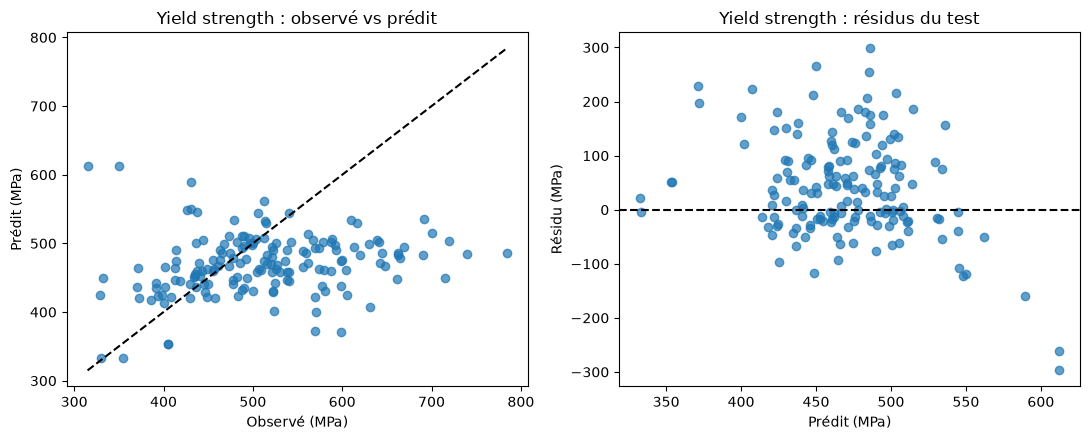

In [71]:
target_results = {}
target_results["Yield strength"] = evaluate_target("Yield strength")
display_target_result(target_results["Yield strength"])

### b) Ultimate tensile strength

La résistance maximale à la traction est la contrainte maximale supportée avant rupture. Elle est elle aussi exprimée en MPa, mais sa population renseignée et son split sont recalculés indépendamment de ceux de `Yield strength`.

Ultimate tensile strength : sélection forward/backward sur la graine 42...
Variables figées : all=25, forward=8, backward=14.
Évaluation de 15 configurations sur 5 graines × 5 folds...
Cible : Ultimate tensile strength (MPa)


,ensemble,lignes,Weld ID,moyenne y,écart-type y
0,train,580,74,597.66,89.0
1,test,158,17,582.38,86.5


Configurations classées par RMSE de validation croisée :


,sélection,alpha,variables,MAE_CV,RMSE_CV,RMSE_std_graines,RMSE_IC95_bas,RMSE_IC95_haut,R2_CV
9,Forward,100.00,8,48.298,63.149,0.134,62.983,63.316,0.482
8,Forward,10.00,8,48.308,63.230,0.153,63.040,63.420,0.479
7,Forward,1.00,8,48.467,63.441,0.155,63.249,63.633,0.475
6,Forward,0.10,8,48.486,63.466,0.155,63.274,63.659,0.475
5,Forward,0.01,8,48.488,63.469,0.155,63.277,63.661,0.475
12,Backward,1.00,14,49.357,65.594,0.560,64.898,66.290,0.412
11,Backward,0.10,14,49.286,65.612,0.544,64.937,66.287,0.411
10,Backward,0.01,14,49.281,65.616,0.542,64.943,66.289,0.411
13,Backward,10.00,14,50.015,65.909,0.618,65.142,66.676,0.410
14,Backward,100.00,14,51.147,68.219,0.363,67.768,68.670,0.375


Meilleure stratégie : Forward ; alpha = 100 ; RMSE CV répétée = 63.15 MPa ; IC95 = [62.98 ; 63.32]
Historique forward (graine 42) :


,step,feature_changed,variables,rmse_mean,rmse_ci95_low,rmse_ci95_high
0,1,Chromium concentration,1,77.248,67.304,87.192
1,2,Manganese concentration,2,71.917,58.017,85.817
2,3,Molybdenum concentration,3,68.807,55.600,82.014
3,4,Nickel concentration,4,66.124,60.417,71.830
4,5,Carbon concentration,5,65.106,62.818,67.394
5,6,Phosphorus concentration,6,64.092,60.610,67.574
6,7,Copper concentration,7,63.631,60.448,66.815
7,8,Post weld heat treatment temperature,8,63.495,59.521,67.470


Historique backward (graine 42) :


,step,feature_changed,variables,rmse_mean,rmse_ci95_low,rmse_ci95_high
0,0,NaN,25,82.188,70.148,94.228
1,1,Chromium concentration,24,75.926,63.018,88.835
2,2,Electrode positive or negative,23,73.835,62.661,85.010
3,3,Nitrogen concentration,22,72.518,58.237,86.800
4,4,Type of weld,21,68.828,57.720,79.936
5,5,Sulphur concentration,20,68.254,56.737,79.771
6,6,Heat input,19,67.353,57.636,77.070
7,7,Boron concentration,18,66.876,56.114,77.638
8,8,Oxygen concentration,17,66.486,55.762,77.210
9,9,Interpass temperature,16,66.300,55.669,76.932


8 variables retenues :


,variable
0,Carbon concentration
1,Manganese concentration
2,Phosphorus concentration
3,Nickel concentration
4,Chromium concentration
5,Molybdenum concentration
6,Copper concentration
7,Post weld heat treatment temperature


,MAE,RMSE,R2,NRMSE
Baseline,71.994,87.567,-0.031,1.012
Pipeline,55.197,70.597,0.330,0.816


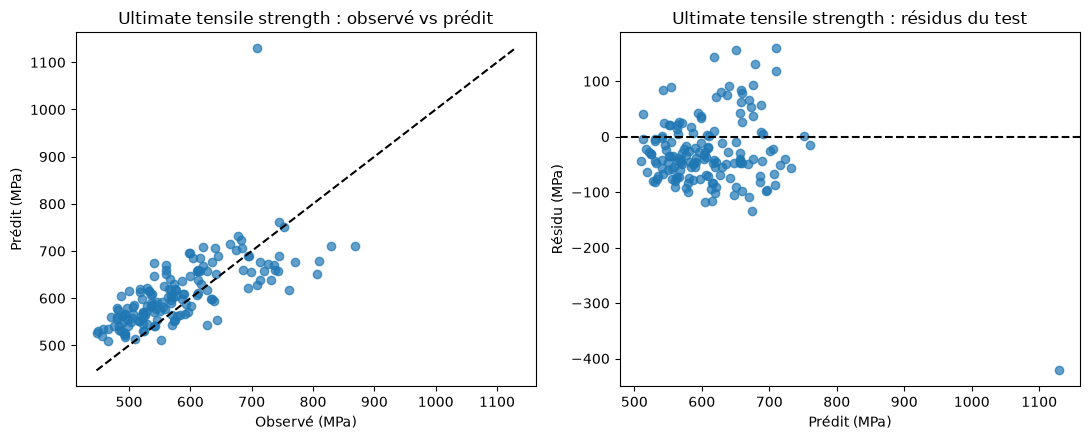

In [72]:
target_results["Ultimate tensile strength"] = evaluate_target("Ultimate tensile strength")
display_target_result(target_results["Ultimate tensile strength"])

### c) Elongation

L'élongation mesure la ductilité. Ses erreurs sont exprimées en points de pourcentage ; elles ne doivent donc pas être comparées directement aux erreurs en MPa des deux résistances.

Elongation : sélection forward/backward sur la graine 42...
Variables figées : all=25, forward=14, backward=14.
Évaluation de 15 configurations sur 5 graines × 5 folds...
Cible : Elongation (%)


,ensemble,lignes,Weld ID,moyenne y,écart-type y
0,train,557,70,26.36,4.82
1,test,143,16,25.96,5.21


Configurations classées par RMSE de validation croisée :


,sélection,alpha,variables,MAE_CV,RMSE_CV,RMSE_std_graines,RMSE_IC95_bas,RMSE_IC95_haut,R2_CV
9,Forward,100.00,14,2.989,3.741,0.021,3.714,3.767,0.393
14,Backward,100.00,14,2.989,3.741,0.021,3.714,3.767,0.393
8,Forward,10.00,14,3.027,3.802,0.043,3.749,3.855,0.373
13,Backward,10.00,14,3.027,3.802,0.043,3.749,3.855,0.373
7,Forward,1.00,14,3.007,3.805,0.052,3.740,3.870,0.372
12,Backward,1.00,14,3.007,3.805,0.052,3.740,3.870,0.372
6,Forward,0.10,14,3.008,3.815,0.055,3.746,3.883,0.369
11,Backward,0.10,14,3.008,3.815,0.055,3.746,3.883,0.369
5,Forward,0.01,14,3.008,3.817,0.056,3.747,3.886,0.368
10,Backward,0.01,14,3.008,3.817,0.056,3.747,3.886,0.368


Meilleure stratégie : Forward ; alpha = 100 ; RMSE CV répétée = 3.74 % ; IC95 = [3.71 ; 3.77]
Historique forward (graine 42) :


,step,feature_changed,variables,rmse_mean,rmse_ci95_low,rmse_ci95_high
0,1,Molybdenum concentration,1,4.297,3.586,5.008
1,2,Niobium concentration,2,4.077,3.733,4.421
2,3,Manganese concentration,3,3.948,3.558,4.338
3,4,Post weld heat treatment temperature,4,3.869,3.478,4.259
4,5,Oxygen concentration,5,3.836,3.430,4.242
5,6,Carbon concentration,6,3.814,3.396,4.233
6,7,Nickel concentration,7,3.784,3.373,4.195
7,8,Copper concentration,8,3.768,3.392,4.144
8,9,Interpass temperature,9,3.765,3.352,4.178
9,10,Type of weld,10,3.761,3.273,4.248


Historique backward (graine 42) :


,step,feature_changed,variables,rmse_mean,rmse_ci95_low,rmse_ci95_high
0,0,NaN,25,10.416,-1.821,22.654
1,1,Boron concentration,24,5.522,3.176,7.868
2,2,Sulphur concentration,23,4.925,3.595,6.255
3,3,Chromium concentration,22,4.441,3.114,5.767
4,4,Phosphorus concentration,21,4.090,3.414,4.766
5,5,Aluminium concentration,20,3.976,3.464,4.488
6,6,Voltage,19,3.931,3.495,4.366
7,7,Nitrogen concentration,18,3.872,3.469,4.274
8,8,Silicon concentration,17,3.807,3.455,4.159
9,9,Heat input,16,3.748,3.258,4.238


14 variables retenues :


,variable
0,Carbon concentration
1,Manganese concentration
2,Nickel concentration
3,Molybdenum concentration
4,Vanadium concentration
5,Copper concentration
6,Oxygen concentration
7,Titanium concentration
8,Niobium concentration
9,Current


,MAE,RMSE,R2,NRMSE
Baseline,4.291,5.202,-0.006,0.999
Pipeline,4.114,5.053,0.051,0.971


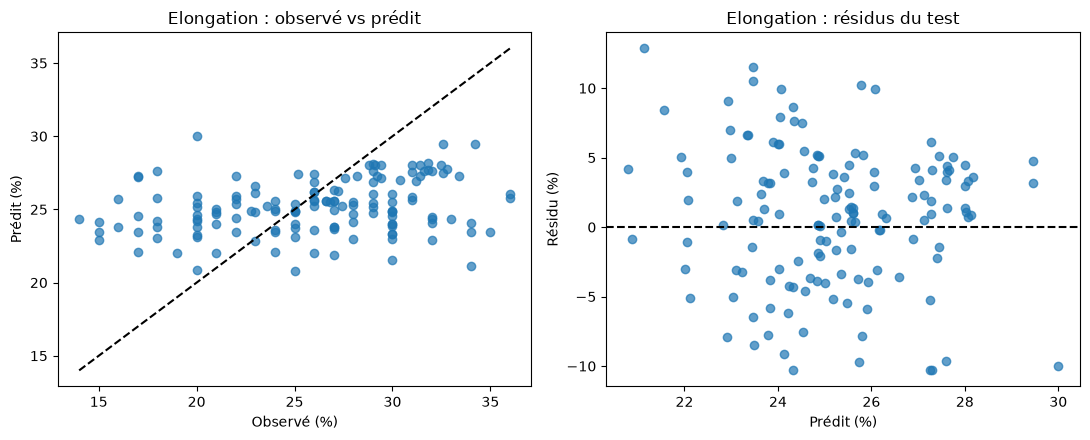

In [73]:
target_results["Elongation"] = evaluate_target("Elongation")
display_target_result(target_results["Elongation"])

### d) Reduction of Area

La réduction de section est une seconde mesure de ductilité à la rupture. Ses erreurs sont exprimées en points de pourcentage. Le même protocole permet de vérifier si cette cible est plus ou moins prévisible que l'élongation.

Reduction of Area : sélection forward/backward sur la graine 42...
Variables figées : all=25, forward=11, backward=10.
Évaluation de 15 configurations sur 5 graines × 5 folds...
Cible : Reduction of Area (%)


,ensemble,lignes,Weld ID,moyenne y,écart-type y
0,train,546,69,72.24,8.77
1,test,159,15,70.28,9.32


Configurations classées par RMSE de validation croisée :


,sélection,alpha,variables,MAE_CV,RMSE_CV,RMSE_std_graines,RMSE_IC95_bas,RMSE_IC95_haut,R2_CV
9,Forward,100.00,11,3.706,5.511,0.074,5.420,5.603,0.585
14,Backward,100.00,10,3.785,5.536,0.065,5.456,5.617,0.585
13,Backward,10.00,10,3.893,5.539,0.144,5.360,5.719,0.574
12,Backward,1.00,10,3.931,5.565,0.159,5.367,5.762,0.567
11,Backward,0.10,10,3.935,5.568,0.160,5.369,5.767,0.567
10,Backward,0.01,10,3.936,5.568,0.161,5.369,5.768,0.567
8,Forward,10.00,11,3.834,5.580,0.131,5.418,5.742,0.564
7,Forward,1.00,11,3.912,5.706,0.051,5.642,5.769,0.548
6,Forward,0.10,11,4.076,5.931,0.015,5.913,5.950,0.512
5,Forward,0.01,11,4.104,5.977,0.021,5.951,6.003,0.503


Meilleure stratégie : Forward ; alpha = 100 ; RMSE CV répétée = 5.51 % ; IC95 = [5.42 ; 5.60]
Historique forward (graine 42) :


,step,feature_changed,variables,rmse_mean,rmse_ci95_low,rmse_ci95_high
0,1,Type of weld,1,7.685,5.471,9.899
1,2,Molybdenum concentration,2,6.793,4.455,9.132
2,3,Sulphur concentration,3,6.609,4.503,8.714
3,4,Nickel concentration,4,6.459,4.763,8.154
4,5,Manganese concentration,5,6.327,4.675,7.979
5,6,Copper concentration,6,6.246,4.730,7.762
6,7,Current,7,6.167,4.403,7.932
7,8,Niobium concentration,8,6.109,4.306,7.911
8,9,Silicon concentration,9,6.048,4.423,7.672
9,10,Chromium concentration,10,5.796,3.818,7.773


Historique backward (graine 42) :


,step,feature_changed,variables,rmse_mean,rmse_ci95_low,rmse_ci95_high
0,0,NaN,25,8.459,6.162,10.756
1,1,Type of weld,24,7.655,5.307,10.003
2,2,Boron concentration,23,7.064,5.626,8.502
3,3,Voltage,22,6.825,5.310,8.339
4,4,Chromium concentration,21,6.671,4.765,8.576
5,5,Aluminium concentration,20,6.541,4.950,8.131
6,6,Phosphorus concentration,19,6.436,4.981,7.891
7,7,Heat input,18,6.323,4.933,7.713
8,8,Titanium concentration,17,6.133,4.580,7.686
9,9,Post weld heat treatment temperature,16,6.046,4.488,7.605


11 variables retenues :


,variable
0,Silicon concentration
1,Manganese concentration
2,Sulphur concentration
3,Nickel concentration
4,Chromium concentration
5,Molybdenum concentration
6,Vanadium concentration
7,Copper concentration
8,Niobium concentration
9,Current


,MAE,RMSE,R2,NRMSE
Baseline,7.348,9.500,-0.045,1.019
Pipeline,4.728,6.275,0.544,0.673


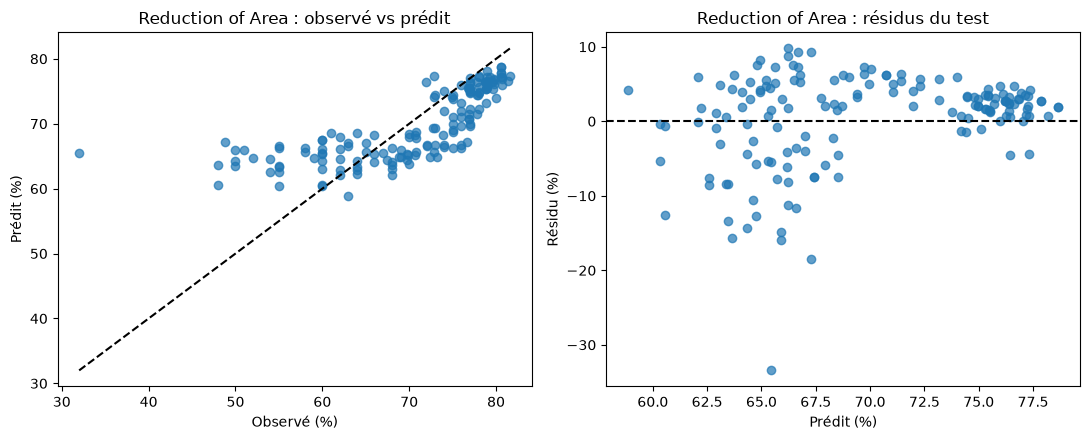

In [74]:
target_results["Reduction of Area"] = evaluate_target("Reduction of Area")
display_target_result(target_results["Reduction of Area"])

## 7. Synthèse des quatre cibles

Les MAE et RMSE brutes ne sont comparables qu'entre modèles d'une même cible, car les unités et les amplitudes changent. Pour comparer la difficulté des quatre problèmes, on privilégie le $R^2$ et la `NRMSE`, définie comme la RMSE divisée par l'écart-type de la cible dans le test. Une `NRMSE` inférieure à celle de la baseline et un $R^2$ positif indiquent un gain par rapport à la prédiction constante.

Le tableau rapporte également la stratégie choisie, la régularisation et le nombre de variables finales. Il faut interpréter ces choix comme des résultats du protocole de validation, et non comme une preuve de causalité physique.

In [75]:
summary_rows = []
for target, result in target_results.items():
    best = result["cv_table"].iloc[0]
    summary_rows.append({
        "cible": target,
        "unité": result["unit"],
        "lignes": len(result["split"]["y_train"]) + len(result["split"]["y_test"]),
        "Weld ID": (result["split"]["groups_train"].nunique()
                    + result["split"]["groups_test"].nunique()),
        "stratégie": best["sélection"],
        "alpha": best["alpha"],
        "variables": len(result["selected_features"]),
        "RMSE CV répétée": best["RMSE_CV"],
        "IC95 bas": best["RMSE_IC95_bas"],
        "IC95 haut": best["RMSE_IC95_haut"],
        "RMSE baseline": result["baseline_scores"]["RMSE"],
        "RMSE test": result["model_scores"]["RMSE"],
        "NRMSE test": result["model_scores"]["NRMSE"],
        "R2 test": result["model_scores"]["R2"],
    })
summary = pd.DataFrame(summary_rows).set_index("cible")
display(summary.round(3))

,unité,lignes,Weld ID,stratégie,alpha,variables,RMSE CV répétée,IC95 bas,IC95 haut,RMSE baseline,RMSE test,NRMSE test,R2 test
cible,,,,,,,,,,,,,
Yield strength,MPa,780,92,Backward,10.0,14,71.073,70.386,71.761,90.155,101.138,1.119,-0.260
Ultimate tensile strength,MPa,738,91,Forward,100.0,8,63.149,62.983,63.316,87.567,70.597,0.816,0.330
Elongation,%,700,86,Forward,100.0,14,3.741,3.714,3.767,5.202,5.053,0.971,0.051
Reduction of Area,%,705,84,Forward,100.0,11,5.511,5.420,5.603,9.500,6.275,0.673,0.544


### Lecture des résultats obtenus

Après réexécution, la synthèse distingue deux niveaux. La `RMSE CV répétée` et son IC à 95 % décrivent la stabilité de chaque configuration entre les cinq graines d'évaluation. La `RMSE test` mesure ensuite une seule fois la généralisation aux lots gelés. L'IC de CV ne doit donc pas être présenté comme un intervalle autour de la RMSE test.

La configuration est choisie sur la plus petite RMSE CV répétée. Comme ces mêmes répétitions servent au choix de la stratégie et de $\alpha$, leur score peut rester légèrement optimiste ; le test final demeure la référence non consultée pendant la recherche. Les variables retenues sont prédictives dans ce protocole, sans implication causale.

## 8. Contrôles anti-fuite

Les assertions finales vérifient les mêmes garanties pour chacun des quatre modèles : aucun `Weld ID` partagé entre train et test, aucune cible ni condition Charpy parmi les prédicteurs, sélection sur les colonnes brutes avant prétraitement, standardisation apprise dans la pipeline et identifiant retiré avant Ridge.

In [76]:
for target, result in target_results.items():
    fitted = result["best_pipeline"]
    selected_columns = set(fitted.named_steps["select"].columns)
    split = result["split"]
    assert ID_COL in selected_columns
    assert not set(ALL_TARGETS).intersection(selected_columns)
    assert "Charpy temperature" not in selected_columns
    assert set(split["groups_train"]).isdisjoint(set(split["groups_test"]))
    assert set(result["cv_plan"]) == set(EVALUATION_CV_SEEDS)
    assert set(result["selection_cv_plan"]) == {SELECTION_CV_SEED}
    assert (result["selectors"]["forward"].cv_seed ==
            result["selectors"]["backward"].cv_seed == SELECTION_CV_SEED)
    for splits in result["cv_plan"].values():
        for train_idx, valid_idx in splits:
            assert set(split["groups_train"].iloc[train_idx]).isdisjoint(
                set(split["groups_train"].iloc[valid_idx])
            )
    assert result["selected_features"].tolist() == result["feature_sets"][
        result["best_params"]["strategy"]
    ]
    assert isinstance(
        fitted.named_steps["preprocess"].named_transformers_["num"]
        .named_steps["scale"], StandardScaler
    )
    raw_test = fitted.named_steps["select"].transform(split["X_test"])
    selected_test = fitted.named_steps["feature_selection"].transform(raw_test)
    assert ID_COL not in selected_test.columns
    assert selected_test.columns.tolist() == result["selected_features"].tolist()
    transformed = fitted.named_steps["preprocess"].transform(selected_test)
    assert transformed.shape[1] == len(
        fitted.named_steps["preprocess"].get_feature_names_out()
    )
print("Contrôles validés pour les quatre cibles : groupes, variables et transformations sans fuite.")

Contrôles validés pour les quatre cibles : groupes, variables et transformations sans fuite.


## 9. Conclusion de la partie I

Cette première partie construit une évaluation commune et sans fuite de données pour les quatre propriétés mécaniques. Le découpage est effectué par `Weld ID` : un même lot ne peut jamais apparaître à la fois dans le train et dans le test. La sélection est apprise une seule fois sur les variables brutes avec cinq folds et une graine fixe. L'imputation, l'encodage et la standardisation sont ajustés dans chaque sous-train après cette sélection.

Les ensembles complet, forward et backward sont ensuite figés et comparés avec cinq valeurs de $\alpha$ sur cinq nouvelles graines de CV. L'intervalle à 95 % est calculé sur les cinq RMSE moyennes par graine. Le pipeline gagnant est enfin réentraîné sur tout le train et évalué une seule fois sur le test gelé.

Ridge fournit ainsi une référence linéaire régularisée adaptée aux variables corrélées. La partie II teste deux modèles capables d'apprendre automatiquement des seuils, des interactions et des relations non linéaires, sans modifier les groupes train/test déjà définis.

# II) Random Forest Regressor et Extra Trees

`RandomForestRegressor` construit chaque arbre à partir d'un échantillon bootstrap et d'un sous-ensemble aléatoire de variables. `ExtraTreesRegressor` ajoute davantage d'aléa en tirant aussi les seuils de coupure ; il est souvent plus rapide et peut réduire la variance, au prix d'un biais parfois plus élevé.

Les deux modèles sont comparés dans une seule recherche sur le train avec les mêmes 5 folds stratifiés sur les quantiles et groupés par `Weld ID`. La grille explore la profondeur, le nombre minimal d'observations par feuille et la proportion de variables proposée à chaque coupure. La configuration qui minimise la RMSE de validation croisée est ensuite la seule évaluée sur le test gelé. Les arbres n'ont pas besoin de standardisation ni de sélection séquentielle : les variables numériques sont seulement imputées par la médiane, et les variables catégorielles sont encodées comme précédemment.

In [77]:
tree_numeric_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median", add_indicator=False)),
])
tree_preprocess = ColumnTransformer([
    ("num", tree_numeric_pipe, NUMERIC),
    ("cat", clone(categorical_pipe), CATEGORICAL),
    ("group", "passthrough", [ID_COL]),
], verbose_feature_names_out=False)
tree_pipeline = Pipeline([
    ("select", DataFrameColumnSelector(FEATURES + [ID_COL])),
    ("preprocess", tree_preprocess),
    ("drop_group", DropGroupColumn()),
    ("model", RandomForestRegressor(random_state=RANDOM_STATE)),
])

def ensemble_name(model):
    if isinstance(model, RandomForestRegressor):
        return "Random Forest"
    if isinstance(model, ExtraTreesRegressor):
        return "Extra Trees"
    return type(model).__name__

def evaluate_tree_target(target):
    """Compare RF et Extra Trees par CV groupée, puis évalue le gagnant sur le test."""
    split = target_populations[target]
    X_train, X_test = split["X_train"], split["X_test"]
    y_train, y_test = split["y_train"], split["y_test"]
    groups_train = split["groups_train"]

    param_grid = [
        {
            "model": [RandomForestRegressor(
                n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1
            )],
            "model__max_depth": [None, 8, 16],
            "model__min_samples_leaf": [1, 3],
            "model__max_features": ["sqrt", 0.7],
        },
        {
            "model": [ExtraTreesRegressor(
                n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1
            )],
            "model__max_depth": [None, 8, 16],
            "model__min_samples_leaf": [1, 3],
            "model__max_features": ["sqrt", 0.7],
        },
    ]
    cv = stratified_group_splits(
        X_train, y_train, groups_train, n_splits=N_SPLITS_CV,
        random_state=SELECTION_CV_SEED,
    )
    search = GridSearchCV(
        clone(tree_pipeline), param_grid,
        cv=cv, n_jobs=1, error_score="raise",
        scoring={"MAE": "neg_mean_absolute_error",
                 "RMSE": "neg_root_mean_squared_error", "R2": "r2"},
        refit="RMSE", return_train_score=True,
    )
    search.fit(X_train, y_train)

    cv_results = pd.DataFrame(search.cv_results_)
    cv_table = pd.DataFrame({
        "modèle": cv_results["param_model"].map(ensemble_name),
        "max_depth": cv_results["param_model__max_depth"],
        "min_samples_leaf": cv_results["param_model__min_samples_leaf"].astype(int),
        "max_features": cv_results["param_model__max_features"],
        "MAE_CV": -cv_results["mean_test_MAE"],
        "RMSE_CV": -cv_results["mean_test_RMSE"],
        "R2_CV": cv_results["mean_test_R2"],
    }).sort_values("RMSE_CV")

    best_pipeline = search.best_estimator_
    pred_test = best_pipeline.predict(X_test)
    feature_names = best_pipeline.named_steps["preprocess"].get_feature_names_out()[:-1]
    importances = pd.Series(
        best_pipeline.named_steps["model"].feature_importances_,
        index=feature_names, name="importance",
    ).sort_values(ascending=False)
    baseline_prediction = np.full(len(y_test), y_train.mean())
    return {
        "target": target, "unit": TARGET_UNITS[target], "split": split,
        "search": search, "cv_table": cv_table,
        "best_pipeline": best_pipeline, "pred_test": pred_test,
        "feature_importances": importances,
        "baseline_scores": regression_scores(y_test, baseline_prediction),
        "model_scores": regression_scores(y_test, pred_test),
    }

def display_tree_result(result):
    target, unit = result["target"], result["unit"]
    search, split = result["search"], result["split"]
    model = result["best_pipeline"].named_steps["model"]
    print(f"Cible : {target} ({unit})")
    print(f"Meilleur modèle : {ensemble_name(model)} ; "
          f"RMSE CV = {-search.best_score_:.2f} {unit}")
    print({key.replace('model__', ''): value
           for key, value in search.best_params_.items() if key != "model"})
    display(result["cv_table"].head(10).round(3))
    display(pd.DataFrame({
        "Baseline": result["baseline_scores"],
        ensemble_name(model): result["model_scores"],
    }).T.round(3))

    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
    y_test, pred_test = split["y_test"], result["pred_test"]
    limits = [min(y_test.min(), pred_test.min()), max(y_test.max(), pred_test.max())]
    axes[0].scatter(y_test, pred_test, alpha=.7)
    axes[0].plot(limits, limits, "k--")
    axes[0].set(xlabel=f"Observé ({unit})", ylabel=f"Prédit ({unit})",
                title=f"{target} : observé vs prédit")
    top_importances = result["feature_importances"].head(15).sort_values()
    axes[1].barh(top_importances.index, top_importances.values)
    axes[1].set(title="15 principales importances", xlabel="Importance")
    plt.tight_layout()
    plt.show()

## 10. Recherche et résultats par cible

La cellule suivante entraîne 24 configurations par cible (12 pour chaque famille), chacune évaluée sur 5 folds groupés. Son exécution peut donc prendre plusieurs minutes.

Cible : Yield strength (MPa)
Meilleur modèle : Extra Trees ; RMSE CV = 60.25 MPa
{'max_depth': None, 'max_features': 0.7, 'min_samples_leaf': 1}


,modèle,max_depth,min_samples_leaf,max_features,MAE_CV,RMSE_CV,R2_CV
14,Extra Trees,None,1,0.7,43.109,60.254,0.569
22,Extra Trees,16,1,0.7,43.889,60.908,0.561
15,Extra Trees,None,3,0.7,45.098,61.564,0.554
23,Extra Trees,16,3,0.7,45.510,61.872,0.549
18,Extra Trees,8,1,0.7,48.389,64.347,0.516
19,Extra Trees,8,3,0.7,49.644,65.500,0.499
0,Random Forest,None,1,sqrt,49.389,66.139,0.492
8,Random Forest,16,1,sqrt,49.848,66.656,0.485
12,Extra Trees,None,1,sqrt,48.305,66.928,0.482
1,Random Forest,None,3,sqrt,50.700,67.210,0.475


,MAE,RMSE,R2,NRMSE
Baseline,71.540,90.155,-0.001,0.998
Extra Trees,61.884,82.294,0.166,0.911


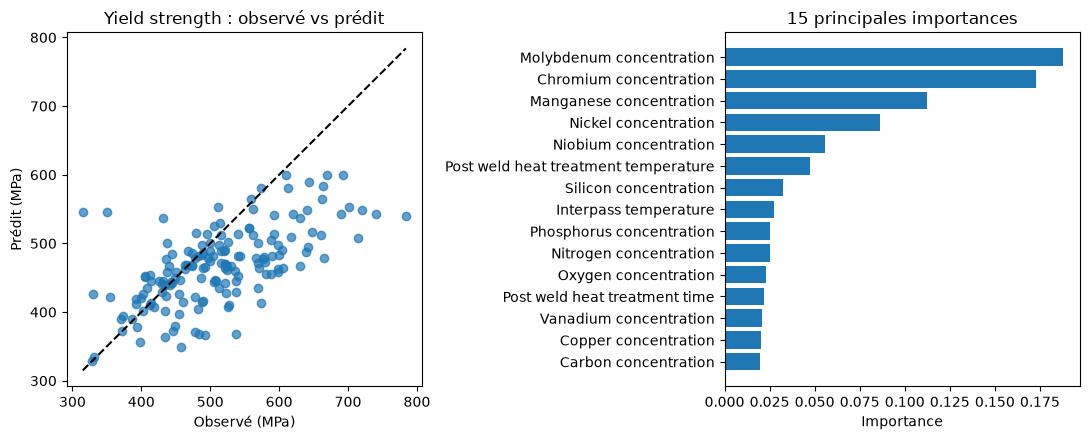

Cible : Ultimate tensile strength (MPa)
Meilleur modèle : Extra Trees ; RMSE CV = 60.41 MPa
{'max_depth': 16, 'max_features': 0.7, 'min_samples_leaf': 1}


,modèle,max_depth,min_samples_leaf,max_features,MAE_CV,RMSE_CV,R2_CV
22,Extra Trees,16,1,0.7,42.637,60.405,0.527
2,Random Forest,None,1,0.7,43.663,60.477,0.531
14,Extra Trees,None,1,0.7,42.375,60.589,0.526
10,Random Forest,16,1,0.7,43.989,60.756,0.526
23,Extra Trees,16,3,0.7,43.606,61.267,0.513
3,Random Forest,None,3,0.7,44.214,61.302,0.516
11,Random Forest,16,3,0.7,44.325,61.410,0.515
7,Random Forest,8,3,0.7,44.997,61.560,0.512
6,Random Forest,8,1,0.7,45.310,61.808,0.508
15,Extra Trees,None,3,0.7,44.007,61.831,0.504


,MAE,RMSE,R2,NRMSE
Baseline,71.994,87.567,-0.031,1.012
Extra Trees,38.814,58.001,0.548,0.671


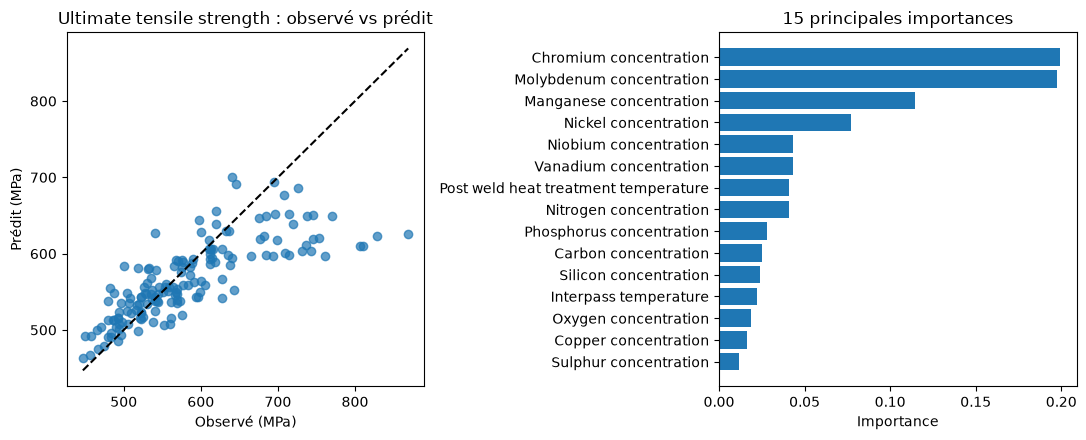

Cible : Elongation (%)
Meilleur modèle : Extra Trees ; RMSE CV = 3.29 %
{'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1}


,modèle,max_depth,min_samples_leaf,max_features,MAE_CV,RMSE_CV,R2_CV
12,Extra Trees,None,1,sqrt,2.527,3.289,0.527
20,Extra Trees,16,1,sqrt,2.657,3.352,0.510
0,Random Forest,None,1,sqrt,2.665,3.405,0.490
8,Random Forest,16,1,sqrt,2.684,3.413,0.488
15,Extra Trees,None,3,0.7,2.630,3.429,0.481
14,Extra Trees,None,1,0.7,2.569,3.437,0.476
23,Extra Trees,16,3,0.7,2.652,3.443,0.477
22,Extra Trees,16,1,0.7,2.651,3.466,0.468
9,Random Forest,16,3,sqrt,2.766,3.479,0.471
1,Random Forest,None,3,sqrt,2.772,3.484,0.469


,MAE,RMSE,R2,NRMSE
Baseline,4.291,5.202,-0.006,0.999
Extra Trees,3.813,4.941,0.092,0.949


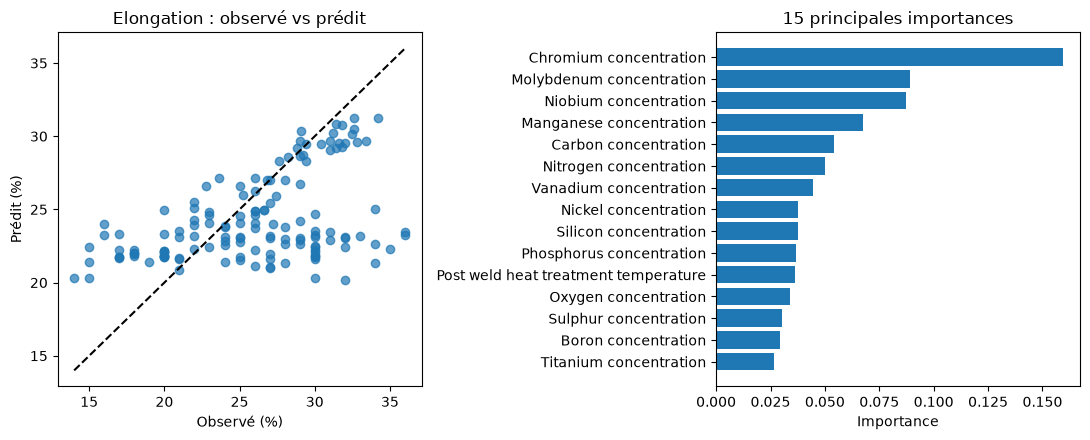

Cible : Reduction of Area (%)
Meilleur modèle : Random Forest ; RMSE CV = 5.99 %
{'max_depth': 16, 'max_features': 'sqrt', 'min_samples_leaf': 1}


,modèle,max_depth,min_samples_leaf,max_features,MAE_CV,RMSE_CV,R2_CV
8,Random Forest,16,1,sqrt,3.740,5.994,0.520
0,Random Forest,None,1,sqrt,3.731,6.000,0.518
1,Random Forest,None,3,sqrt,3.742,6.020,0.517
9,Random Forest,16,3,sqrt,3.743,6.033,0.514
4,Random Forest,8,1,sqrt,3.853,6.040,0.513
5,Random Forest,8,3,sqrt,3.855,6.100,0.503
21,Extra Trees,16,3,sqrt,3.809,6.166,0.489
13,Extra Trees,None,3,sqrt,3.785,6.168,0.489
17,Extra Trees,8,3,sqrt,3.895,6.219,0.480
12,Extra Trees,None,1,sqrt,3.802,6.229,0.476


,MAE,RMSE,R2,NRMSE
Baseline,7.348,9.500,-0.045,1.019
Random Forest,4.081,6.214,0.553,0.666


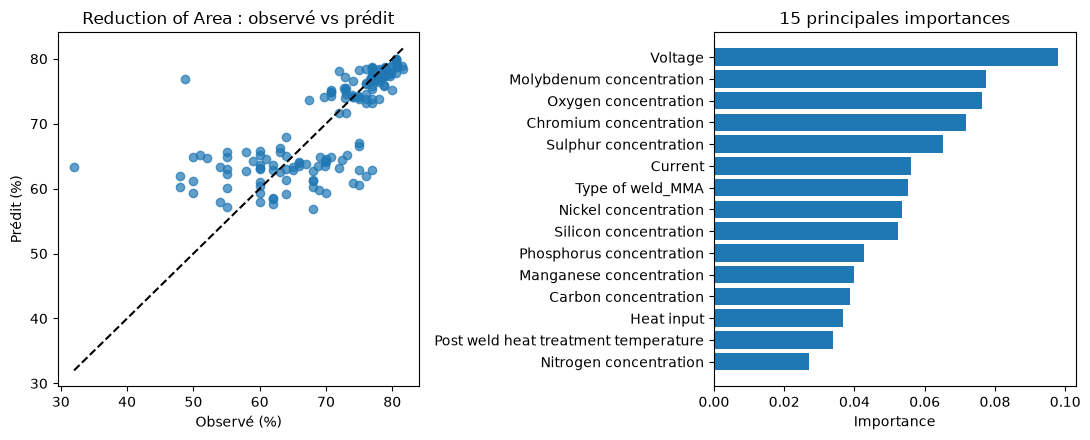

In [78]:
tree_results = {}
for target in MECHANICAL_TARGETS:
    tree_results[target] = evaluate_tree_target(target)
    display_tree_result(tree_results[target])

## 11. Comparaison finale avec Ridge

La comparaison ci-dessous utilise exactement les mêmes observations de test pour les trois lignes d'une cible. Le gain de RMSE est positif lorsque le meilleur ensemble d'arbres améliore Ridge. Le choix entre Random Forest et Extra Trees provient exclusivement de la validation croisée sur le train, jamais du score de test. Les importances indiquent l'utilité prédictive des variables pour le modèle ; elles ne démontrent pas une relation causale.

In [79]:
comparison_rows = []
for target in MECHANICAL_TARGETS:
    ridge_result = target_results[target]
    tree_result = tree_results[target]
    tree_model = tree_result["best_pipeline"].named_steps["model"]
    ridge_rmse = ridge_result["model_scores"]["RMSE"]
    tree_rmse = tree_result["model_scores"]["RMSE"]
    comparison_rows.append({
        "cible": target,
        "ensemble retenu": ensemble_name(tree_model),
        "RMSE baseline": tree_result["baseline_scores"]["RMSE"],
        "RMSE Ridge": ridge_rmse,
        "R2 Ridge": ridge_result["model_scores"]["R2"],
        "RMSE arbres": tree_rmse,
        "R2 arbres": tree_result["model_scores"]["R2"],
        "gain RMSE vs Ridge (%)": 100 * (ridge_rmse - tree_rmse) / ridge_rmse,
    })
comparison = pd.DataFrame(comparison_rows).set_index("cible")
display(comparison.round(3))

,ensemble retenu,RMSE baseline,RMSE Ridge,R2 Ridge,RMSE arbres,R2 arbres,gain RMSE vs Ridge (%)
cible,,,,,,,
Yield strength,Extra Trees,90.155,101.138,-0.260,82.294,0.166,18.632
Ultimate tensile strength,Extra Trees,87.567,70.597,0.330,58.001,0.548,17.842
Elongation,Extra Trees,5.202,5.053,0.051,4.941,0.092,2.209
Reduction of Area,Random Forest,9.500,6.275,0.544,6.214,0.553,0.965


## 12. Conclusion générale

Après réexécution complète, le tableau précédent permet de déterminer cible par cible si les ensembles d'arbres améliorent le nouveau Ridge sélectionné par CV répétée. Un gain positif de RMSE suggère que des non-linéarités ou des interactions entre paramètres de soudage apportent une information prédictive supplémentaire.

Les scores de test doivent être commentés tels quels, y compris lorsqu'un $R^2$ est négatif. Comme ce même test a déjà été observé dans la partie Ridge, cette extension constitue une comparaison exploratoire. Pour une estimation définitive après ce nouveau choix de familles de modèles, il faudrait disposer d'un second jeu de test encore intact ou utiliser une validation croisée externe groupée.

In [80]:
for target, result in tree_results.items():
    fitted = result["best_pipeline"]
    split = result["split"]
    assert isinstance(fitted.named_steps["model"],
                      (RandomForestRegressor, ExtraTreesRegressor))
    assert set(split["groups_train"]).isdisjoint(set(split["groups_test"]))
    assert ID_COL in fitted.named_steps["select"].columns
    assert not set(ALL_TARGETS).intersection(fitted.named_steps["select"].columns)
    transformed = fitted.named_steps["preprocess"].transform(split["X_test"])
    without_group = fitted.named_steps["drop_group"].transform(transformed)
    assert without_group.shape[1] == fitted.named_steps["model"].n_features_in_
print("Contrôles validés pour les modèles d'ensemble : groupes et variables sans fuite.")

Contrôles validés pour les modèles d'ensemble : groupes et variables sans fuite.
